In [1]:
import numpy as np
import matplotlib.pyplot as plt
import celmech
import rebound
from sympy import totient
from scipy.special import erfc
from celmech.maps import EncounterMap
from scipy.signal import find_peaks

import warnings #to catch warning in implicit update
warnings.simplefilter("error", RuntimeWarning)

In [2]:
class NamouniMap():
    r"""
    A class representing the Namouni map. The map depends on parameters,
    :math:`K`, :math:`\phi`, :math:`\lambda`, and :math:`I`. The map is defined by the equations

    .. math::
        \begin{align}
        I_{n+1} &= I_n + W_\phi(I_{n+1},K_{n+1},\lambda_n,\phi_n) \\
        \phi_{n+1} &= \phi_n + W_\I(I_{n+1},K_{n+1},\lambda_n,\phi_n) \\
        K_{n+1} = I_{n+1}-I_n+K_n \\
        \lambda_{n+1} = \lambda_n + \frac{4\pi}{3\epsilon\sqrt{8K_{n+1}/3}}
        \end{align}


    See also Namouni et al. (1996)

    Parameters
    ----------
    m : float
        Planet-star mass ratio.
    e0 : float
        Initial eccentricity of the test particle
    a_r0 : float
        Initial relative semimajor axis in Hill's unit
    lambda0 : float
        Initial conjunction longitude
    phi0 : float
        Initial pericenter longitude
    ind : int
        An integer that indicates the configuration of the planetary system. 
        If ind == 1, the massive planet comes before the test particle.
        Otherwise, the test particle comes first.
    exact_period : bool, optional
        If True, the update for lambda_{n+1} will be calculated as in Duncan et al. (1989), 
        which is the exact calculation.
        Otherwise, the update will follow the original Namouni mapping which is the approximation in Hill's limit.
        Default is True.
    """

    
    def __init__(self,m,ind,order,exact_period=True):
        self._m = m
        self._ind = ind
        # self._Nmax = Nmax
        # self._y0 = y0
        # self._update_amplitudes()
        # self.mod = mod
        self._order = order
        self.exact_period = exact_period

    @property
    def m(self):
        return self._m

    @property
    def ind(self):
        return self._ind

    @property
    def order(self):
        return self._order
    
    @property
    def epsilon(self):
        m = self._m
        return (m/3)**(1/3) 

    @property
    def exact_period(self):
        return self._exact_period
        
    @exact_period.setter
    def exact_period(self,val):
        self._exact_period = val
        if val:
            self._periodfn = lambda Knp1: 2*np.pi*np.abs(1/((1+np.sqrt(8*Knp1/3)*self.epsilon)**(-3/2)-1))
        else:
            self._periodfn = lambda Knp1: 4*np.pi/(3*self.epsilon*np.sqrt(8*Knp1/3))

    def namouni_fo_step(self, In, Kn, phin, lambdan, arn, ind):
        """First-order Namouni mapping step."""
        
        W101 = 3.359350011
        hn = np.sqrt(2*In)*np.cos(phin)
        kn = np.sqrt(2*In)*np.sin(phin)
        if ind == 1:
            hprime = hn + 2*W101*np.sin(lambdan)/arn**2 # + for Namouni, - for pomega
            kprime = kn - 2*W101*np.cos(lambdan)/arn**2 # - for Namouni, + for pomega
        else: #from DQT, the sign switches for the outer pair
            hprime = hn - 2*W101*np.sin(lambdan)/arn**2
            kprime = kn + 2*W101*np.cos(lambdan)/arn**2 

        phiprime = np.arctan2(kprime, hprime) # 4 quadrant arctan
        #print(hn, kn)
        # both options should give the same result:
        Iprime = 1/2*(hprime**2 + kprime**2)
        #Namouni update
        hnp1 = hprime
        knp1 = kprime
        Inp1 = Iprime
        Knp1 = Kn + (Inp1 - In)
        phinp1 = phiprime

        lambdanp1 = lambdan + self._periodfn(Knp1)
        # if exact_period==True:
        #     lambdanp1 = lambdan + 2*np.pi*np.abs(1/((1+np.sqrt(8*Knp1/3)*epsilon)**(-3/2)-1)) #same lambda
        # else:
        #     lambdanp1 = lambdan + 4*np.pi/(3*epsilon*np.sqrt(8*Knp1/3))
        return Inp1, Knp1, phinp1, lambdanp1, hnp1, knp1


    def namouni_so_step(self, In, Kn, phin, lambdan, arn, ind):
        """Second-order Namouni mapping step."""
        """The second order mapping involves an intermediate step and implicit scheme for eccentricity update."""
        """This calculates the implicit update iteratively instead of explicitly solving for the next value."""
        W200= -1
        W101= 3.359350011
        W202= -2.678665722        
        hn = np.sqrt(2*In)*np.cos(phin)
        kn = np.sqrt(2*In)*np.sin(phin)
        if ind == 1:
            hprime = hn + 2*W101*np.sin(lambdan)/arn**2 # + for Namouni, - for pomega
            kprime = kn - 2*W101*np.cos(lambdan)/arn**2 # - for Namouni, + for pomega

        else: #from DQT, the sign switches for the outer pair
            hprime = hn - 2*W101*np.sin(lambdan)/arn**2
            kprime = kn + 2*W101*np.cos(lambdan)/arn**2 

        phiprime = np.arctan2(kprime, hprime) # 4 quadrant arctan
        #thetaprime = (pomegaprime - lambdan)
        thetaprime = (phiprime - lambdan)
    
        # A = calc_coeff(2, W2, arn, thetaprime)
        # E1 = 1/(1+A)
        # Inp1 = E1*Inprime
        #implicit I update
        Iprime = 0.5*(hprime**2 + kprime**2)
        
        Inp1_prev = Iprime #first guess = Iprime
        while True: #iteratively update using implicit scheme
            Inp1_next = Iprime - 4*W202*np.sin(2*thetaprime)*2*Inp1_prev/arn**3
            if np.abs((Inp1_next-Inp1_prev)/Inp1_next) < 1e-12: #break when satisfied
                break
            Inp1_prev = Inp1_next
        # Inp1 = (0.5*(hprime**2 + kprime**2)) / (1 + 4*W2*np.sin(2*thetaprime)*2/arn**3)
        Inp1 = Inp1_next
    
        #pomeganp1 = pomegaprime - (W200 + 2*W2*np.cos(2*thetaprime))*2/arn**3
        phinp1 = phiprime - (W200 + 2*W202*np.cos(2*thetaprime))*2/arn**3
        Knp1 = Kn + Inp1 - In
        # Knp1 = Kn + (Inp1 - In)*arn**2 #Istar scale
        hnp1 = np.sqrt(2*Inp1)*np.cos(phinp1)
        knp1 = np.sqrt(2*Inp1)*np.sin(phinp1)
        lambdanp1 = lambdan + self._periodfn(Knp1)
        # if exact_period==True:
        #     lambdanp1 = lambdan + 2*np.pi*np.abs(1/((1+np.sqrt(8*Knp1/3)*epsilon)**(-3/2)-1)) #same lambda
        # else:
        #     lambdanp1 = lambdan + 4*np.pi/(3*epsilon*np.sqrt(8*Knp1/3))
        return Inp1, Knp1, phinp1, lambdanp1, hnp1, knp1



    def namouni_4o_step(self, In, Kn, phin, lambdan, arn, ind):
        """Fourth-order Namouni mapping step."""
        """The fourth order mapping involves an intermediate step and implicit scheme for eccentricity update."""
        """This calculates the implicit update iteratively instead of explicitly solving for the next value."""
        W200, W400= -1,-3/8
        W101, W301 = 3.359350011, 0.1430675142
        W202, W402 = -2.678665722, 0.5232506456
        W303 = 2.639498803
        W404 = -2.855951527
        hn = np.sqrt(2*In)*np.cos(phin)
        kn = np.sqrt(2*In)*np.sin(phin)
   
        if ind == 1:
            hprime = hn + 2*W101*np.sin(lambdan)/arn**2 # + for Namouni, - for pomega
            kprime = kn - 2*W101*np.cos(lambdan)/arn**2 # - for Namouni, + for pomega

        else: #from DQT, the sign switches for the outer pair
            hprime = hn - 2*W101*np.sin(lambdan)/arn**2
            kprime = kn + 2*W101*np.cos(lambdan)/arn**2 
 
        phiprime = np.arctan2(kprime, hprime) # 4 quadrant arctan
        #thetaprime = (pomegaprime - lambdan)
        thetaprime = (phiprime - lambdan)
    
        # A = calc_coeff(2, W2, arn, thetaprime)
        # E1 = 1/(1+A)
        # Inp1 = E1*Inprime
        #implicit I update
        Iprime = 0.5*(hprime**2 + kprime**2)
        
        Inp1_prev = Iprime #first guess = Iprime
        phinp1_prev = phiprime
        try:
            while True: #iteratively update using implicit scheme
                Inp1o1 = 2*(W301/arn**4*(2*Inp1_prev)**1.5)*np.sin(thetaprime)
                Inp1o2 = 4*W202*np.sin(2*thetaprime)*2*Inp1_prev/arn**3
                Inp1o3 = (2*W301*np.sin(thetaprime)+6*W303*np.sin(3*thetaprime))*(2*Inp1_prev)**(3/2)/arn**4
                Inp1o4 = (4*W402*np.sin(2*thetaprime)+8*W404*np.sin(4*thetaprime))*(2*Inp1_prev)**(2)/arn**5

                Inp1_next = Iprime - Inp1o1 - Inp1o2 - Inp1o3 - Inp1o4
                
                phinp1o2 = (W200 + 2*W202*np.cos(2*thetaprime))*2/arn**3
                phinp1o3 = 3*2**(3/2)*(W301*np.cos(thetaprime)+W303*np.cos(3*thetaprime))*Inp1_prev**0.5/arn**4
                phinp1o4 = 8*(W400+2*W402*np.cos(2*thetaprime)+2*W404*np.cos(4*thetaprime))*Inp1_prev/arn**5
                phinp1_next = phiprime - (phinp1o2+phinp1o3+phinp1o4)
                if np.abs((Inp1_next-Inp1_prev)/Inp1_next) < 1e-12 and np.abs((phinp1_next-phinp1_prev)/phinp1_next) < 1e-12: 
                    #break when satisfied
                    break
                Inp1_prev = Inp1_next
                phinp1_prev = phinp1_next
        except RuntimeWarning as e:
            print("Inp1 candidate", Inp1_prev)
            print("Iprime", Iprime)
        Inp1 = Inp1_next
        phinp1 = phinp1_next
        Knp1 = Kn + Inp1 - In
        # Knp1 = Kn + (Inp1 - In)*arn**2 #Istar scale
        hnp1 = np.sqrt(2*Inp1)*np.cos(phinp1)
        knp1 = np.sqrt(2*Inp1)*np.sin(phinp1)
        lambdanp1 = lambdan + self._periodfn(Knp1)
        # if exact_period==True:
        #     lambdanp1 = lambdan + 2*np.pi*np.abs(1/((1+np.sqrt(8*Knp1/3)*epsilon)**(-3/2)-1)) #same lambda
        # else:
        #     lambdanp1 = lambdan + 4*np.pi/(3*epsilon*np.sqrt(8*Knp1/3))
        return Inp1, Knp1, phinp1, lambdanp1, hnp1, knp1

    def namouni_10o_step(self, In, Kn, phin, lambdan, arn, ind):
        """Tenth-order Namouni mapping step."""
        """The tenth order mapping involves an intermediate step and implicit scheme for eccentricity update."""
        """This calculates the implicit update iteratively instead of explicitly solving for the next value."""
        #define all coeffs in here so that we won't get confused
        #format WABC = W^{A,B}_C
        W200, W400, W600, W800, W1000 = -1,-3/8,-5/24,-35/256,-63/640
        W101, W301, W501, W701, W901 = 3.359350011, 0.1430675142, 0.2652528982, 0.1598760057, 0.1125398541
        W202, W402, W602, W802, W1002 = -2.678665722, 0.5232506456, -0.2880525893, -0.1146109541, -0.09264257446
        W303, W503, W703, W903 = 2.639498803, -1.270297850, 0.5079066956, 0.04027194541
        W404, W604, W804, W1004 = -2.855951527, 2.244981532, -1.030263325, 0.1370220235
        W505, W705, W905 = 3.259400253, -3.586274249, 2.034584646
        W606, W806, W1006 = -3.850815349, 5.467708834, -3.807558748
        W707, W907 = 4.661571101, -8.124434579
        W808, W1008 = -5.745863967, 11.88290720
        W909 = 7.181868977
        W10010 = -9.077037610
        hn = np.sqrt(2*In)*np.cos(phin)
        kn = np.sqrt(2*In)*np.sin(phin)
     
        if ind == 1:
            hprime = hn + 2*W101*np.sin(lambdan)/arn**2 # + for Namouni, - for pomega
            kprime = kn - 2*W101*np.cos(lambdan)/arn**2 # - for Namouni, + for pomega
            # hprime = hn + 2*W101*np.sin(lambdan)/arn
            # kprime = kn - 2*W101*np.cos(lambdan)/arn
        else: #from DQT, the sign switches for the outer pair
            hprime = hn - 2*W101*np.sin(lambdan)/arn**2
            kprime = kn + 2*W101*np.cos(lambdan)/arn**2 
            # hprime = hn - 2*W101*np.sin(lambdan)/arn
            # kprime = kn + 2*W101*np.cos(lambdan)/arn
        phiprime = np.arctan2(kprime, hprime) # 4 quadrant arctan
        #thetaprime = (pomegaprime - lambdan)
        thetaprime = (phiprime - lambdan)
    
        
        #implicit I update
        Iprime = 0.5*(hprime**2 + kprime**2)
        
        Inp1_prev = Iprime #first guess = Iprime
        phinp1_prev = phiprime
        try:
            while True: #iteratively update using implicit scheme
                Inp1o1 = 2*(W301/arn**4*(2*Inp1_prev)**1.5+W501/arn**6*(2*Inp1_prev)**2.5+W701/arn**8*(2*Inp1_prev)**3.5+W901/arn**10*(2*Inp1_prev)**4.5)*np.sin(thetaprime)
                Inp1o2 = 4*(W202/arn**3*(2*Inp1_prev)+W402/arn**5*(2*Inp1_prev)**2+W602/arn**7*(2*Inp1_prev)**3+W802/arn**9*(2*Inp1_prev)**4+W1002/arn**11*(2*Inp1_prev)**5)*np.sin(2*thetaprime)
                Inp1o3 = 6*(W303/arn**4*(2*Inp1_prev)**1.5+W503/arn**6*(2*Inp1_prev)**2.5+W703/arn**8*(2*Inp1_prev)**3.5+W903/arn**10*(2*Inp1_prev)**4.5)*np.sin(3*thetaprime)
                Inp1o4 = 8*(W404/arn**5*(2*Inp1_prev)**2+W604/arn**7*(2*Inp1_prev)**3+W804/arn**9*(2*Inp1_prev)**4+W1004/arn**11*(2*Inp1_prev)**5)*np.sin(4*thetaprime)
                Inp1o5 = 10*(W505/arn**6*(2*Inp1_prev)**2.5+W705/arn**8*(2*Inp1_prev)**3.5+W905/arn**10*(2*Inp1_prev)**4.5)*np.sin(5*thetaprime)
                Inp1o6 = 12*(W606/arn**7*(2*Inp1_prev)**3+W806/arn**9*(2*Inp1_prev)**4+W1006/arn**11*(2*Inp1_prev)**5)*np.sin(6*thetaprime)
                Inp1o7 = 14*(W707/arn**8*(2*Inp1_prev)**3.5+W907/arn**10*(2*Inp1_prev)**4.5)*np.sin(7*thetaprime)
                Inp1o8 = 16*(W808/arn**9*(2*Inp1_prev)**4+W1008/arn**11*(2*Inp1_prev)**5)*np.sin(8*thetaprime)
                Inp1o9 = 18*(W909/arn**10*(2*Inp1_prev)**4.5)*np.sin(9*thetaprime)
                Inp1o10 = 20*(W10010/arn**11*(2*Inp1_prev)**5)*np.sin(10*thetaprime)
           
        
                Inp1_next = Iprime-Inp1o1-Inp1o2-Inp1o3-Inp1o4-Inp1o5-Inp1o6-Inp1o7-Inp1o8-Inp1o9-Inp1o10
                
                phinp1o0 = W200*2/arn**3+W400*2**2*2*Inp1_prev/arn**5+W600*2**3*3*Inp1_prev**2/arn**7+W800*2**4*4*Inp1_prev**3/arn**9+W1000*2**5*5*Inp1_prev**4/arn**11
                phinp1o1 = 2*(W301*2**1.5*1.5*Inp1_prev**0.5/arn**4+W501*2**2.5*2.5*Inp1_prev**1.5/arn**6+W701*2**3.5*3.5*Inp1_prev**2.5/arn**8+W901*2**4.5*4.5*Inp1_prev**3.5/arn**10)*np.cos(thetaprime)
                phinp1o2 = 2*(W202*2/arn**3+W402*2**2*2*Inp1_prev/arn**5+W602*2**3*3*Inp1_prev**2/arn**7+W802*2**4*4*Inp1_prev**3/arn**9+W1002*2**5*5*Inp1_prev**4/arn**11)*np.cos(2*thetaprime)
                phinp1o3 = 2*(W303*2**1.5*1.5*Inp1_prev**0.5/arn**4+W503*2**2.5*2.5*Inp1_prev**1.5/arn**6+W703*2**3.5*3.5*Inp1_prev**2.5/arn**8+W903*2**4.5*4.5*Inp1_prev**3.5/arn**10)*np.cos(3*thetaprime)
                phinp1o4 = 2*(W404*2**2*2*Inp1_prev/arn**5+W604*2**3*3*Inp1_prev**2/arn**7+W804*2**4*4*Inp1_prev**3/arn**9+W1004*2**5*5*Inp1_prev**4/arn**11)*np.cos(4*thetaprime)
                phinp1o5 = 2*(W505*2**2.5*2.5*Inp1_prev**1.5/arn**6+W705*2**3.5*3.5*Inp1_prev**2.5/arn**8+W905*2**4.5*4.5*Inp1_prev**3.5/arn**10)*np.cos(5*thetaprime)
                phinp1o6 = 2*(W606*2**3*3*Inp1_prev**2/arn**7+W806*2**4*4*Inp1_prev**3/arn**9+W1006*2**5*5*Inp1_prev**4/arn**11)*np.cos(6*thetaprime)
                phinp1o7 = 2*(W707*2**3.5*3.5*Inp1_prev**2.5/arn**8+W907*2**4.5*4.5*Inp1_prev**3.5/arn**10)*np.cos(7*thetaprime)
                phinp1o8 = 2*(W808*2**4*4*Inp1_prev**3/arn**9+W1008*2**5*5*Inp1_prev**4/arn**11)*np.cos(8*thetaprime)
                phinp1o9 = 2*(W909*2**4.5*4.5*Inp1_prev**3.5/arn**10)*np.cos(9*thetaprime)
                phinp1o10 = 2*(W10010*2**5*5*Inp1_prev**4/arn**11)*np.cos(10*thetaprime)

                phinp1_next = phiprime-phinp1o0-phinp1o1-phinp1o2-phinp1o3-phinp1o4-phinp1o5-phinp1o6-phinp1o7-phinp1o8-phinp1o9-phinp1o10
                if np.abs((Inp1_next-Inp1_prev)/Inp1_next) < 1e-12 and np.abs((phinp1_next-phinp1_prev)/phinp1_next) < 1e-12: 
                    #break when satisfied
                    break
                Inp1_prev = Inp1_next
                phinp1_prev = phinp1_next
    
        except RuntimeWarning as e:
            print("Inp1 candidate", Inp1_prev)
            print("Iprime", Iprime)
                
            
            
        Inp1 = Inp1_next
        phinp1 = phinp1_next
        Knp1 = Kn + Inp1 - In
        # Knp1 = Kn + (Inp1 - In)*arn**2 #Istar scale
        hnp1 = np.sqrt(2*Inp1)*np.cos(phinp1)
        knp1 = np.sqrt(2*Inp1)*np.sin(phinp1)
        lambdanp1 = lambdan + self._periodfn(Knp1)
        # if exact_period==True:
        #     lambdanp1 = lambdan + 2*np.pi*np.abs(1/((1+np.sqrt(8*Knp1/3)*epsilon)**(-3/2)-1)) #same lambda
        # else:
        #     lambdanp1 = lambdan + 4*np.pi/(3*epsilon*np.sqrt(8*Knp1/3))
        return Inp1, Knp1, phinp1, lambdanp1, hnp1, knp1

        #This function runs Namouni mapping for multiple conjunctions
    def runmap(self, I0, K0, phi0, lambda0, Nconj, order):
        try:                # minimize function later passes a 1-element list, so make it work for both scalar and list
            K0 = K0[0]
        except:
            pass
        Is, Ks, phis, lambdas, hs, ks = np.zeros(Nconj+1), np.zeros(Nconj+1), np.zeros(Nconj+1), np.zeros(Nconj+1), np.zeros(Nconj+1), np.zeros(Nconj+1)
        Is[0] = I0
        Ks[0] = K0
        phis[0] = phi0
        lambdas[0] = lambda0
        ar0 = np.sqrt(8*K0/3)
        for i in range(Nconj):
            if order==1:
                Is[i+1], Ks[i+1], phis[i+1], lambdas[i+1], hs[i+1], ks[i+1] = self.namouni_fo_step(Is[i], Ks[i], phis[i], lambdas[i], ar0, ind)
            elif order==2:
                Is[i+1], Ks[i+1], phis[i+1], lambdas[i+1], hs[i+1], ks[i+1] = self.namouni_so_step(Is[i], Ks[i], phis[i], lambdas[i], ar0, ind)
            elif order==4:
                Is[i+1], Ks[i+1], phis[i+1], lambdas[i+1], hs[i+1], ks[i+1] = self.namouni_4o_step(Is[i], Ks[i], phis[i], lambdas[i], ar0, ind)
            elif order==10:
                Is[i+1], Ks[i+1], phis[i+1], lambdas[i+1], hs[i+1], ks[i+1] = self.namouni_10o_step(Is[i], Ks[i], phis[i], lambdas[i], ar0, ind)

        return Is, Ks, phis, lambdas, hs, ks
    
    def __call__(self,X,Nconj,order):
        epsilon = self.epsilon
        e0, a_r0, phi0, lambda0 = X
        I0 = (e0/epsilon)**2/2
        K0 = 3/8*a_r0**2
    
        Is, Ks, phis, lambdas, hs, ks = self.runmap(I0, K0, phi0, lambda0, Nconj, order)
        return Is, Ks, phis, lambdas, hs, ks


In [3]:
def setup_tri(j, k, mutot, etilde, pomega2, lambda_target, ind, iterations = 10):
    ecross = 2*k/(3*j)
    n1 = 2*np.pi
    n2 = n1*(j-k)/j
    tconj = 2*np.pi/(n1-n2) # estimate for time between conjunctions
    t0 = -0.8*tconj

    lambda10 = lambda_target+n1*t0 # this should be exact since 
    lambda20 = lambda_target+n2*t0

    setupSim=rebound.Simulation()
    setupSim.add(m=1)
    
    if ind == 1:
        setupSim.add(P=j/(j-k), e=etilde*ecross, pomega=pomega2, l=lambda_target)
        x_target = setupSim.particles[1].x
    else:
        setupSim.add(P=1, e=etilde*ecross, pomega=pomega2, l=lambda_target)
        x_target = setupSim.particles[1].x

    if ind == 1: #inner pair
        lambda_20_prev = lambda20 # initial guess
        correction = 0
        for i in range(iterations):
            lambda_20 = lambda_20_prev + correction
            sim = rebound.Simulation()
            sim.add(m=1)
            sim.add(primary=sim.particles[0], m=mutot, P=1, l=lambda10)
            sim.add(primary=sim.particles[0], P=j/(j-k), e=etilde*ecross, pomega=pomega2, l=lambda_20)
            var_l = sim.add_variation()
            var_l.vary(2, 'l') # how does everything depend on the initial l of particles[2]
            sim.t = t0
            ps = sim.particles
            
            sim.integrate(0)
            correction = (x_target - ps[2].x)/var_l.particles[2].x
            lambda_20_prev = lambda_20
            #print('***',i,'***')
            #print(lambda_20_prev, ps[2].l, lambda_target-ps[2].l, correction)
        
       
        lambda_20 = lambda_20_prev + correction
        sim = rebound.Simulation()
        sim.add(m=1)
        sim.add(primary=sim.particles[0], m=mutot, P=1, l=lambda10)
        sim.add(primary=sim.particles[0], P=j/(j-k), e=etilde*ecross, pomega=pomega2, l=lambda_20)
    else: #outer pair
        lambda_10_prev = lambda10 # initial guess
        correction = 0
        for i in range(iterations):
            lambda_10 = lambda_10_prev + correction
            sim = rebound.Simulation()
            sim.add(m=1)
            sim.add(primary=sim.particles[0],P=1,e=etilde*ecross, pomega=pomega2, l=lambda_10)
            sim.add(primary=sim.particles[0],m=mutot, P=j/(j-k), l=lambda20)
            var_l = sim.add_variation()
            var_l.vary(1, 'l') # how does everything depend on the initial l of particles[2]
            sim.t = t0
            ps = sim.particles
        
            sim.integrate(0)
            correction = (x_target - ps[1].x)/var_l.particles[1].x
            lambda_10_prev = lambda_10
            #print('***',i,'***')
            #print(lambda_10_prev, ps[2].l, lambda_target-ps[2].l, correction)
        
       
        lambda_10 = lambda_10_prev + correction
        sim = rebound.Simulation()
        sim.add(m=1)
        sim.add(primary=sim.particles[0], P=1,e=etilde*ecross, pomega=pomega2, l=lambda_10)
        sim.add(primary=sim.particles[0], m=mutot, P=j/(j-k), l=lambda20)
    sim.t = t0
    return sim

In [4]:
def setup_four(a1, a2, mutot, ecc, pomega2, lambda_target, ind, iterations = 0):
    #setup for planets not in exact resonance - takes in noninteger values of period ratio
    if ind == 1:
        ap = a1
        a = a2
    else:
        ap = a2
        a = a1
    ecross = (a-ap)/ap
    Pratio = (a2/a1)**1.5
    n1 = 2*np.pi
    n2 = n1/Pratio
    tconj = 2*np.pi/(n1-n2) # estimate for time between conjunctions
    t0 = -0.8*tconj

    lambda10 = lambda_target+n1*t0 # this should be exact since 
    lambda20 = lambda_target+n2*t0

    setupSim=rebound.Simulation()
    setupSim.add(m=1)
    
    if ind == 1:
        setupSim.add(a=a2, e=ecc, pomega=pomega2, l=lambda_target)
        x_target = setupSim.particles[1].x
    else:
        setupSim.add(a=a1, e=ecc, pomega=pomega2, l=lambda_target)
        x_target = setupSim.particles[1].x

    if ind == 1: #inner pair
        lambda_20_prev = lambda20 # initial guess
        correction = 0
        for i in range(iterations):
            lambda_20 = lambda_20_prev + correction
            sim = rebound.Simulation()
            sim.add(m=1)
            sim.add(primary=sim.particles[0], m=mutot, a=a1, l=lambda10)
            sim.add(primary=sim.particles[0], a=a2, e=ecc, pomega=pomega2, l=lambda_20)
            var_l = sim.add_variation()
            var_l.vary(2, 'l') # how does everything depend on the initial l of particles[2]
            sim.t = t0
            ps = sim.particles
            
            sim.integrate(0)
            correction = (x_target - ps[2].x)/var_l.particles[2].x
            lambda_20_prev = lambda_20
            #print('***',i,'***')
            #print(lambda_20_prev, ps[2].l, lambda_target-ps[2].l, correction)
        
       
        lambda_20 = lambda_20_prev + correction
        sim = rebound.Simulation()
        sim.add(m=1)
        sim.add(primary=sim.particles[0], m=mutot, a=a1, l=lambda10)
        sim.add(primary=sim.particles[0], a=a2, e=ecc, pomega=pomega2, l=lambda_20)
    else: #outer pair
        lambda_10_prev = lambda10 # initial guess
        correction = 0
        for i in range(iterations):
            lambda_10 = lambda_10_prev + correction
            sim = rebound.Simulation()
            sim.add(m=1)
            sim.add(primary=sim.particles[0],a=a1,e=ecc, pomega=pomega2, l=lambda_10)
            sim.add(primary=sim.particles[0],m=mutot, a=a2, l=lambda20)
            var_l = sim.add_variation()
            var_l.vary(1, 'l') # how does everything depend on the initial l of particles[2]
            sim.t = t0
            ps = sim.particles
        
            sim.integrate(0)
            correction = (x_target - ps[1].x)/var_l.particles[1].x
            lambda_10_prev = lambda_10
            #print('***',i,'***')
            #print(lambda_10_prev, ps[2].l, lambda_target-ps[2].l, correction)
        
       
        lambda_10 = lambda_10_prev + correction
        sim = rebound.Simulation()
        sim.add(m=1)
        sim.add(primary=sim.particles[0], a=a1,e=ecc, pomega=pomega2, l=lambda_10)
        sim.add(primary=sim.particles[0], m=mutot, a=a2, l=lambda20)
    sim.t = t0
    return sim

In [5]:
def unwrap_l(ps):
    ''' given a sim.particles object ps, returns relative lambda (l) value of the planets
        removing the 2*pi discontinuities that result when one planet has crossed l=0 but
        the other has not
    '''
    if ps[2].l - ps[1].l > np.pi:
        return ps[2].l - ps[1].l - 2*np.pi
    elif ps[2].l - ps[1].l < -np.pi:
        return ps[2].l - ps[1].l + 2*np.pi
    else:
        return ps[2].l - ps[1].l

In [6]:
def new_run(sim, Nconj, Nout, ind):
    '''
    This function runs the Nbody simulation until we get Nconj conjunctions 
    and save the orbital parameters and conjunction times.
    '''
    # this function now saves individual semimajor axis length and other individual variables (will keep adding)
    ps = sim.particles
    n1 = ps[1].n
    n2 = ps[2].n
    tmin = sim.t
    #print(tmin)
    tconj = 2*np.pi/(n1-n2)
    tmax = Nconj*tconj + 0.8*tmin

    a12_arr, l12_arr, l2, theta_arr, pomega_arr, e12_arr, diffn_arr = np.zeros(Nout), np.zeros(Nout), np.zeros(Nout), np.zeros(Nout), np.zeros(Nout), np.zeros(Nout), np.zeros(Nout)
    e1, e2, pomega1, pomega2, a1_arr, a2_arr = np.zeros(Nout), np.zeros(Nout), np.zeros(Nout), np.zeros(Nout), np.zeros(Nout), np.zeros(Nout)
    n1_arr, n2_arr = np.zeros(Nout), np.zeros(Nout)
    l1 = np.zeros(Nout)
    times = np.linspace(tmin, tmax, Nout)
    #print(times)
    for i, time in enumerate(times):
        if ind==1:
            a12_arr[i] = (ps[2].a - ps[1].a)/ps[1].a # relative semimajor axis (a-a_p)/a_p
        else:
            a12_arr[i] = (ps[1].a - ps[2].a)/ps[2].a # now the second index is the planet
        a1_arr[i] = ps[1].a
        a2_arr[i] = ps[2].a
        l12_arr[i] = unwrap_l(ps) 
        e1_vec_temp= ps[1].e * np.exp(1j * ps[1].pomega)
        e2_vec_temp= ps[2].e * np.exp(1j * ps[2].pomega)
        if ind==1:
            pomega12_temp = np.angle(e2_vec_temp-e1_vec_temp)
            e12_temp = np.abs(e2_vec_temp-e1_vec_temp)
        else:
            pomega12_temp = np.angle(e1_vec_temp-e2_vec_temp)
            e12_temp = np.abs(e1_vec_temp-e2_vec_temp)
        theta_arr[i] = ps[2].l - pomega12_temp

        l1[i] = ps[1].l
        l2[i] = ps[2].l
        pomega_arr[i] = pomega12_temp
        e12_arr[i] = e12_temp

        n1_arr[i] = ps[1].n
        n2_arr[i] = ps[2].n
        e1[i] = ps[1].e
        e2[i] = ps[2].e
        pomega1[i] = ps[1].pomega
        pomega2[i] = ps[2].pomega
        diffn_arr[i] = ps[1].n - ps[2].n
        sim.integrate(time)

    l1 = np.unwrap(l1)
    l2 = np.unwrap(l2)
    
    # conjunctions occur at minima pf dl = maxima of -dl
    conj_idx, _ = find_peaks(-np.abs(l12_arr))
    if len(conj_idx) != Nconj:
        print("WARNING: wrong number of conjunction events found \n {} conjunctions found, {} conjunctions input".format(len(conj_idx), Nconj))
        #raise Exception('''wrong number of conjunction events found \n {} conjunctions found, 
        #                {} conjunctions input'''.format(len(conj_idx), Nconj))
    #pts_btwn_conj = (.5*np.diff(conj_idx)).astype(np.int64)

    btwn_conj_idx, properties = find_peaks(np.abs(l12_arr))
    #btwn_conj_idx[1:] = conj_idx[:-1] + pts_btwn_conj

    return [times, a12_arr, l12_arr, theta_arr, l1, l2, pomega_arr, e12_arr, e1, e2, pomega1, pomega2, diffn_arr, conj_idx, btwn_conj_idx, a1_arr, a2_arr, n1_arr, n2_arr]


In [7]:
#for four panel plot - first condition, 3:2
Npts = 60
#range setup and mass parameter
x0_arr = np.linspace(0,0.25,Npts)
epsilon = (1e-6/3)**(1/3)
mutot = 3*epsilon**3 #mass of the planet
#mean motion resonance ratio
J = 3 #J:J-1 resonance
# for nbody
j = J 
k = 1
#orbit setup - Namouni
a1 = 1
a2 = (J/(J-1))**(2/3)*a1
ecross = (a2-a1)/a1
ar_res = ecross/epsilon
ecc = 3*epsilon

ind = 1# 1 for inner pair, 3 for outer pair
order = 10
lambda0 = 0
phi0 = 0
e0 = ecc

#orbit setup - nbody
pomega2=0
lambda_target= np.pi # where we want conjunction to happen/ analogous to lambda0 in lizzy's

Nconj = 1000 #number of conjunctions
Nout = Nconj*100

# ecross = 2*k/(3*j)
# ecc = 0.05*epsilon
etilde = ecc/ecross
print(etilde)
ar0_list = (1+x0_arr)*ar_res
K0_list = 3/8*ar0_list**2
I0 = (e0/epsilon)**2/2
C = K0_list[0]-I0 # conserved quantity
I_list = K0_list - C #for the same conserved quantity
e0_list = np.sqrt(2*I_list)*epsilon

0.06701933663382854


In [8]:
%%time
#ar0_list = np.linspace(13.33447880751,  15.5, Na) # list of a = a2-a1 values

# print(I0)
ar_conj32 = np.zeros((len(ar0_list), Nconj+1))
theta_conj32 = np.zeros((len(ar0_list), Nconj+1))
K_conj32 = np.zeros((len(ar0_list), Nconj+1))
I_conj32 = np.zeros((len(ar0_list), Nconj+1))
n_map = NamouniMap(mutot,ind,order)

for i, ar in enumerate(ar0_list):
    e0 = e0_list[i]
    a_r0 = ar
    # I0 = n_map.I0
    # K0 = n_map.K0
    #print(e0)
    # initial conditions
    #integrating
    IC = (e0,a_r0,phi0,lambda0)
    Is, Ks, phis, lambdas, hs, ks = n_map(IC,Nconj,order)
    thetas = (phis-lambdas+np.pi) % (2*np.pi) - np.pi
    ar_conj32[i,:] = np.sqrt(8/3*Ks)
    theta_conj32[i,:] = thetas
    I_conj32[i,:] = Is
    K_conj32[i,:] = Ks
ar0_list32 = ar0_list

CPU times: user 12.7 s, sys: 0 ns, total: 12.7 s
Wall time: 12.7 s


In [9]:
%%time
an_all_list32 = []
theta_all_list32 = []
for da in ar0_list:
    a1 = 1
    a2 = a1+a1*da*epsilon
    # print((a2-a1)/a1/epsilon)
    sim = setup_four(a1,a2,mutot,ecc,pomega2,lambda_target,ind)
    
    ps = sim.particles
    # print((ps[2].a-ps[1].a)/ps[1].a/epsilon)
    #parameters from simulation
    times, a12, l12, theta2, l1, l2, pomega12, e12, e1, e2, pomega1_arr, pomega2_arr, diffn_arr, conj_idx, btwn_conj_idx, a1_arr, a2_arr, n1_arr, n2_arr = new_run(sim, Nconj, Nout, ind)
    tconjs = times[conj_idx]  
    tbetweens = times[btwn_conj_idx]  
    an = a12[btwn_conj_idx]              # Relative semimajor axis
    e12n = e12[btwn_conj_idx]            # Relative eccentricity
    #individual values
    a1_conj = a1_arr[btwn_conj_idx] 
    a2_conj = a2_arr[btwn_conj_idx]
    e1_conj = e1[btwn_conj_idx]
    e2_conj = e2[btwn_conj_idx]
    pomega1_conj = pomega1_arr[btwn_conj_idx]
    pomega2_conj = pomega2_arr[btwn_conj_idx]
    pomega12n = pomega12[btwn_conj_idx]    # Relative periapse
    if ind == 1:
        lambdan = l2[conj_idx]               # Lambda at conjunctions
    else:
        lambdan = l1[conj_idx]  
    diffnconj = diffn_arr[conj_idx]
    
    # if Nconj != len(conj_idx):
    #     Nconj = len(conj_idx)
    #     print("wrong number of conjunctions fixed")
    
    # pomega_btwn = pomega_arr[btwn_conj_idx]
    # lambda_conj = l2_arr[conj_idx]
    a_conj = an / epsilon
    an_all_list32.append(a_conj)
    if len(pomega2_conj)==len(lambdan):
        theta_conj = (lambdan-pomega2_conj)%(2*np.pi)
    elif len(pomega2_conj)>len(lambdan):
        theta_conj = (lambdan  - pomega2_conj[:-1])%(2*np.pi)
    elif len(pomega2_conj)<len(lambdan):
        theta_conj = (lambdan[:-1] -  pomega2_conj)%(2*np.pi)
    theta_all_list32.append(theta_conj)
        
#     if len(theta_conj)==len(a_conj):
#         ax3.plot(theta_conj, a_conj, '.', markersize=1) #if using btwn conj index
#     elif len(theta_conj)>len(a_conj):
#         ax3.plot(theta_conj[:-1], a_conj, '.', markersize=1)
#     elif len(theta_conj)<len(a_conj):
#         ax3.plot(theta_conj, a_conj[:-1], '.', markersize=1)
        
# ax3.set_xlabel(r'$\theta = \phi - \lambda_{conj}$')
# ax3.set_ylabel(r'$a_r = a_2 - a_1$')
# ax3.set_title('REBOUND')
# ax3.set_xlim(0, 2*np.pi)
# ax3.set_ylim(ar0_list[0],ar0_list[-1])


 999 conjunctions found, 1000 conjunctions input
CPU times: user 16min 55s, sys: 2.35 s, total: 16min 58s
Wall time: 16min 58s


In [10]:
#for four panel plot - second condition, 10:9
Npts = 70
#range setup and mass parameter
x0_arr = np.linspace(0.00,0.25,Npts)
epsilon = (1e-6/3)**(1/3)
mutot = 3*epsilon**3 #mass of the planet
#mean motion resonance ratio
J = 10 #J:J-1 resonance
# for nbody
j = J 
k = 1
#orbit setup - Namouni
a1 = 1
a2 = (J/(J-1))**(2/3)*a1
ecross = (a2-a1)/a1
ar_res = ecross/epsilon
ecc = 3*epsilon

ind = 1# 1 for inner pair, 3 for outer pair
order = 10
lambda0 = 0
phi0 = 0
e0 = ecc

#orbit setup - nbody
pomega2=0
lambda_target= np.pi # where we want conjunction to happen/ analogous to lambda0 in lizzy's

Nconj = 1000 #number of conjunctions
Nout = Nconj*100

# ecross = 2*k/(3*j)
# ecc = 0.05*epsilon
etilde = ecc/ecross
print(etilde)
ar0_list = (1+x0_arr)*ar_res
K0_list = 3/8*ar0_list**2
I0 = (e0/epsilon)**2/2
C = K0_list[0]-I0 # conserved quantity
I_list = K0_list - C #for the same conserved quantity
e0_list = np.sqrt(2*I_list)*epsilon

0.2858593727854


In [11]:
%%time
ar_conj109 = np.zeros((len(ar0_list), Nconj+1))
theta_conj109 = np.zeros((len(ar0_list), Nconj+1))
K_conj109 = np.zeros((len(ar0_list), Nconj+1))
I_conj109 = np.zeros((len(ar0_list), Nconj+1))
n_map = NamouniMap(mutot,ind,order)

for i, ar in enumerate(ar0_list):
    e0 = e0_list[i]
    a_r0 = ar
    # I0 = n_map.I0
    # K0 = n_map.K0
    #print(e0)
    # initial conditions
    #integrating
    IC = (e0,a_r0,phi0,lambda0)
    Is, Ks, phis, lambdas, hs, ks = n_map(IC,Nconj,order)
    thetas = (phis-lambdas+np.pi) % (2*np.pi) - np.pi
    #thetas = np.where(thetas>np.pi, thetas - 2*np.pi, thetas)
    ar_conj109[i,:] = np.sqrt(8/3*Ks)
    theta_conj109[i,:] = thetas
    I_conj109[i,:] = Is
    K_conj109[i,:] = Ks
ar0_list109 = ar0_list

CPU times: user 22.8 s, sys: 3.98 ms, total: 22.8 s
Wall time: 22.8 s


In [12]:
%%time
an_all_list109 = []
theta_all_list109 = []
for da in ar0_list:
    a1 = 1
    a2 = a1+a1*da*epsilon
    # print((a2-a1)/a1/epsilon)
    sim = setup_four(a1,a2,mutot,ecc,pomega2,lambda_target,ind)
    
    ps = sim.particles
    # print((ps[2].a-ps[1].a)/ps[1].a/epsilon)
    #parameters from simulation
    times, a12, l12, theta2, l1, l2, pomega12, e12, e1, e2, pomega1_arr, pomega2_arr, diffn_arr, conj_idx, btwn_conj_idx, a1_arr, a2_arr, n1_arr, n2_arr = new_run(sim, Nconj, Nout, ind)
    tconjs = times[conj_idx]  
    tbetweens = times[btwn_conj_idx]  
    an = a12[btwn_conj_idx]              # Relative semimajor axis
    e12n = e12[btwn_conj_idx]            # Relative eccentricity
    #individual values
    a1_conj = a1_arr[btwn_conj_idx] 
    a2_conj = a2_arr[btwn_conj_idx]
    e1_conj = e1[btwn_conj_idx]
    e2_conj = e2[btwn_conj_idx]
    pomega1_conj = pomega1_arr[btwn_conj_idx]
    pomega2_conj = pomega2_arr[btwn_conj_idx]
    pomega12n = pomega12[btwn_conj_idx]    # Relative periapse
    if ind == 1:
        lambdan = l2[conj_idx]               # Lambda at conjunctions
    else:
        lambdan = l1[conj_idx]  
    diffnconj = diffn_arr[conj_idx]
    
    # if Nconj != len(conj_idx):
    #     Nconj = len(conj_idx)
    #     print("wrong number of conjunctions fixed")
    
    # pomega_btwn = pomega_arr[btwn_conj_idx]
    # lambda_conj = l2_arr[conj_idx]
    a_conj = an / epsilon
    an_all_list109.append(a_conj)
    if len(pomega2_conj)==len(lambdan):
        theta_conj = (lambdan-pomega2_conj)%(2*np.pi)
    elif len(pomega2_conj)>len(lambdan):
        theta_conj = (lambdan  - pomega2_conj[:-1])%(2*np.pi)
    elif len(pomega2_conj)<len(lambdan):
        theta_conj = (lambdan[:-1] -  pomega2_conj)%(2*np.pi)
    theta_all_list109.append(theta_conj)
        
#     if len(theta_conj)==len(a_conj):
#         ax3.plot(theta_conj, a_conj, '.', markersize=1) #if using btwn conj index
#     elif len(theta_conj)>len(a_conj):
#         ax3.plot(theta_conj[:-1], a_conj, '.', markersize=1)
#     elif len(theta_conj)<len(a_conj):
#         ax3.plot(theta_conj, a_conj[:-1], '.', markersize=1)
        
# ax3.set_xlabel(r'$\theta = \phi - \lambda_{conj}$')
# ax3.set_ylabel(r'$a_r = a_2 - a_1$')
# ax3.set_title('REBOUND')
# ax3.set_xlim(0, 2*np.pi)
# ax3.set_ylim(ar0_list[0],ar0_list[-1])


 997 conjunctions found, 1000 conjunctions input
 993 conjunctions found, 1000 conjunctions input
 990 conjunctions found, 1000 conjunctions input
 995 conjunctions found, 1000 conjunctions input
 997 conjunctions found, 1000 conjunctions input
 998 conjunctions found, 1000 conjunctions input
 998 conjunctions found, 1000 conjunctions input
 998 conjunctions found, 1000 conjunctions input
 999 conjunctions found, 1000 conjunctions input
 1001 conjunctions found, 1000 conjunctions input
 998 conjunctions found, 1000 conjunctions input
 998 conjunctions found, 1000 conjunctions input
 998 conjunctions found, 1000 conjunctions input
 998 conjunctions found, 1000 conjunctions input
 998 conjunctions found, 1000 conjunctions input
 999 conjunctions found, 1000 conjunctions input
 1001 conjunctions found, 1000 conjunctions input
 1001 conjunctions found, 1000 conjunctions input
 1001 conjunctions found, 1000 conjunctions input
 1001 conjunctions found, 1000 conjunctions input
 1002 conjuncti

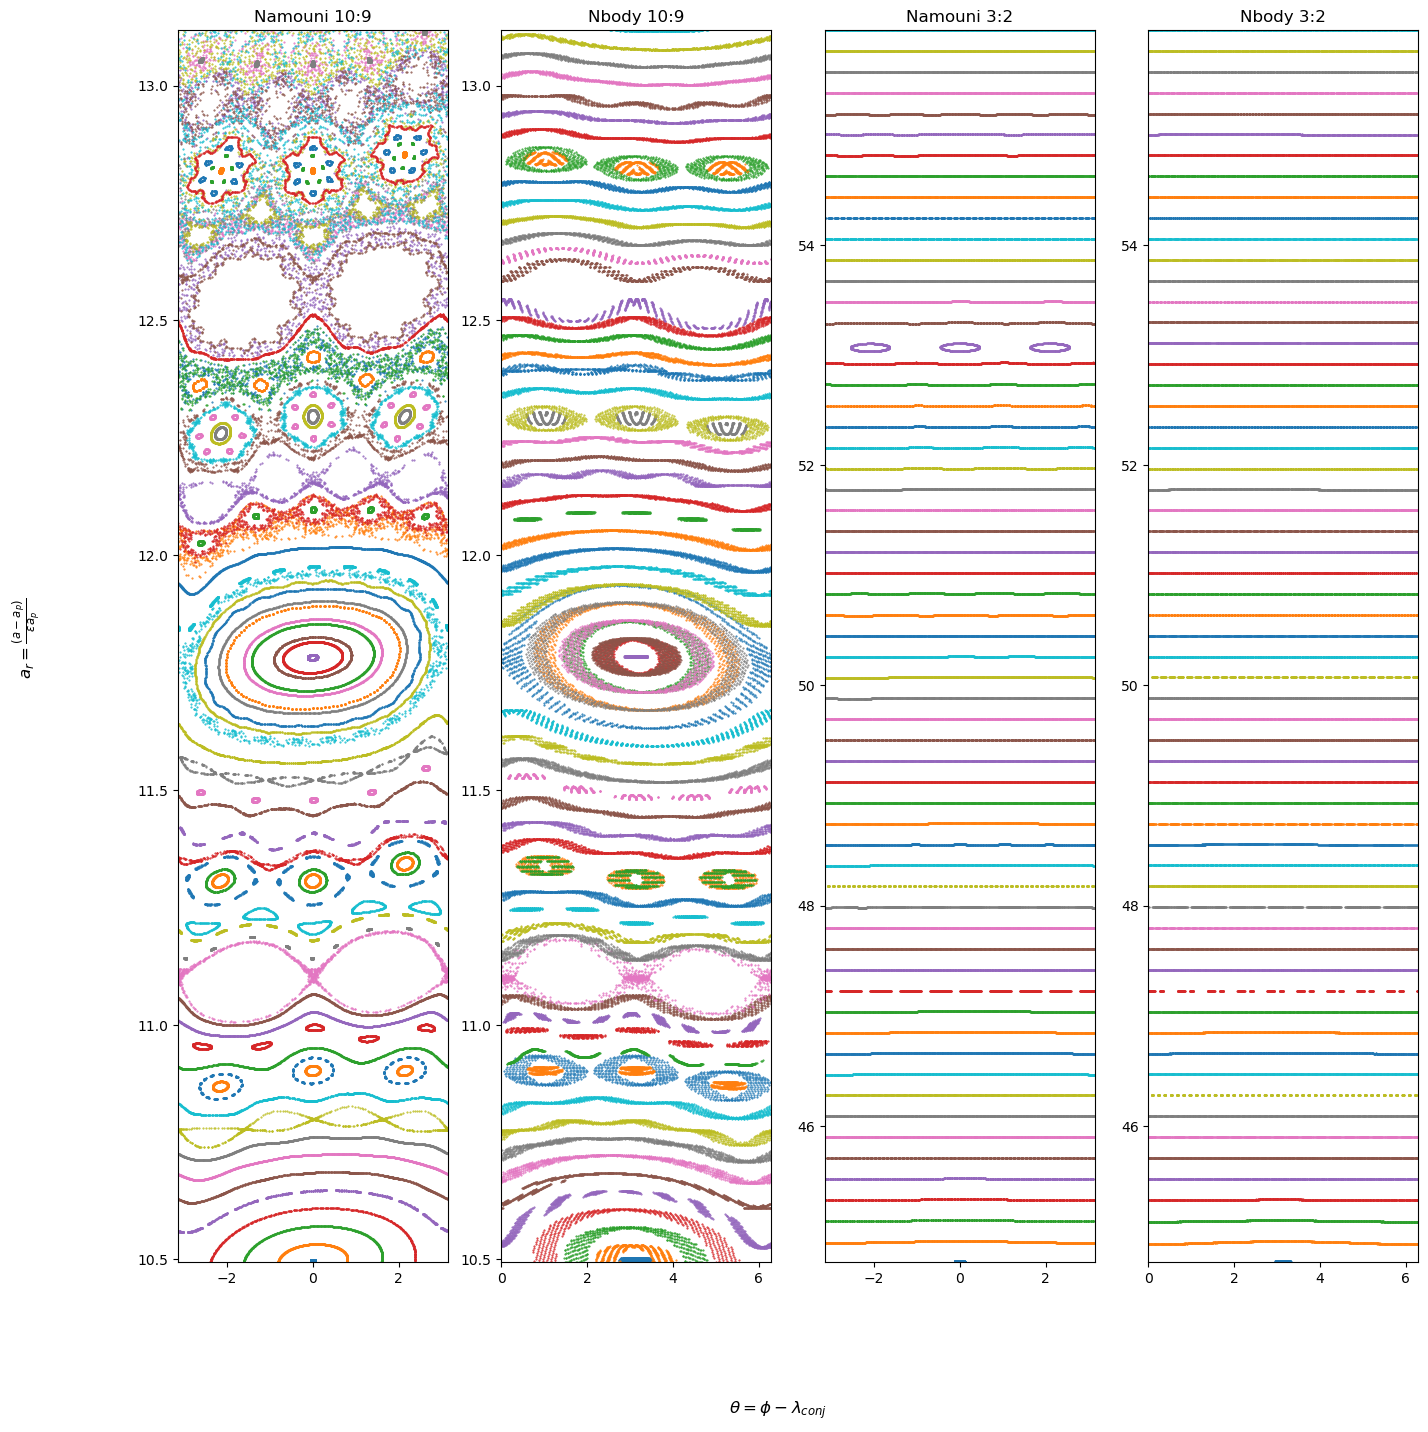

In [13]:
fig, (ax1,ax2,ax3,ax4) = plt.subplots(1,4,figsize=(16,16))
# fig, (ax1,ax2) = plt.subplots(1,2,figsize=(16,16))
fig.supxlabel(r'$\theta = \phi - \lambda_{conj}$')
fig.supylabel(r'$a_r = \frac{(a - a_p)}{\epsilon a_p}$')

ax1.plot(theta_conj109.T, ar_conj109.T, '.', markersize=1,rasterized=True)
ax1.set_title(f'Namouni 10:9')
# ax.set_xlim(-np.pi, np.pi)
ax1.set_xlim(-np.pi, np.pi)
ax1.set_ylim(ar0_list109[0],ar0_list109[-1])

for i in range(len(an_all_list109)):
    if len(theta_all_list109[i])==len(an_all_list109[i]):
        ax2.plot(theta_all_list109[i], an_all_list109[i], '.', markersize=1,rasterized=True)
    elif len(theta_all_list109[i])>len(an_all_list109[i]):
        ax2.plot(theta_all_list109[i][:-1], an_all_list109[i], '.', markersize=1,rasterized=True)
    elif len(theta_all_list109[i])<len(an_all_list109[i]):
        ax2.plot(theta_all_list109[i], an_all_list109[i][:-1], '.', markersize=1,rasterized=True)
ax2.set_title(f'Nbody 10:9')
# # ax.set_xlim(-np.pi, np.pi)
ax2.set_xlim(0, 2*np.pi)
ax2.set_ylim(ar0_list109[0],ar0_list109[-1])


ax3.plot(theta_conj32.T, ar_conj32.T, '.', markersize=1,rasterized=True)
ax3.set_title(f'Namouni 3:2')
# ax.set_xlim(-np.pi, np.pi)
ax3.set_xlim(-np.pi, np.pi)
ax3.set_ylim(ar0_list32[0],ar0_list32[-1])

for i in range(len(an_all_list32)):
    if len(theta_all_list32[i])==len(an_all_list32[i]):
        ax4.plot(theta_all_list32[i], an_all_list32[i], '.', markersize=1,rasterized=True)
    elif len(theta_all_list32[i])>len(an_all_list32[i]):
        ax4.plot(theta_all_list32[i][:-1], an_all_list32[i], '.', markersize=1,rasterized=True)
    elif len(theta_all_list32[i])<len(an_all_list32[i]):
        ax4.plot(theta_all_list32[i], an_all_list32[i][:-1], '.', markersize=1,rasterized=True)
ax4.set_title(f'Nbody 3:2')
# ax.set_xlim(-np.pi, np.pi)
ax4.set_xlim(0, 2*np.pi)
ax4.set_ylim(ar0_list32[0],ar0_list32[-1])
plt.savefig("foursections_exactecross.pdf")